# soundstream — analysis

i trained a soundstream codec for the homework. the main writeup lives in comet (assignment option 1) — this notebook is where i poked at the model myself after training. everything heavy (model load, codec inference, stats) sits in `src/analysis.py`; here i just call into it and write down what i saw and heard.

what i'm covering:

1. in-domain qualitative on librispeech `test-clean` — same corpus family i trained on.
2. out-of-distribution qualitative: two external english clips and two russian clips.
3. quantitative on full test-clean (stoi, nisqa) + a few spectral stats on a 100-utterance subsample.

model i'm analyzing: `final_soundstream.pt`. gan fine-tune on top of a reconstruction-only checkpoint, 45k total steps, 16 khz mono, target 6.4 kbps. on test-clean (n=2620) i got stoi ≈ 0.940 and nisqa v2.0 ≈ 2.52.

to reproduce my setup: `bash scripts/download_checkpoint.sh` and `bash scripts/download_external.sh` once. the two russian clips (fleurs ru_ru, cc by 4.0, see `data/external/russian/SOURCE.md`) are checked into `data/external/russian/` (650 kb total); the loader handles any sample rate / channel count and resamples to 16 khz, so you can drop your own clips in there too.

## setup

i run this notebook from `notebooks/`, so i add the repo root to `sys.path` for `src.analysis` to import cleanly.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))

from src import analysis

## in-domain (librispeech `test-clean`)

matched-distribution check first — 16 khz read english from the same corpus family the codec saw during training. i pulled four utterances from the test manifest covering different speakers and durations.

for each one i look at: waveform overlay (orig vs reconstruction), log-mel of each, and an audio widget so i can a/b them in headphones. if you want different utterances, pass `indices=[...]`.

1089-134686-0000 (10.4s)


1089-134686-0001 (3.3s)


1089-134691-0012 (15.0s)


2300-131720-0028 (25.9s)


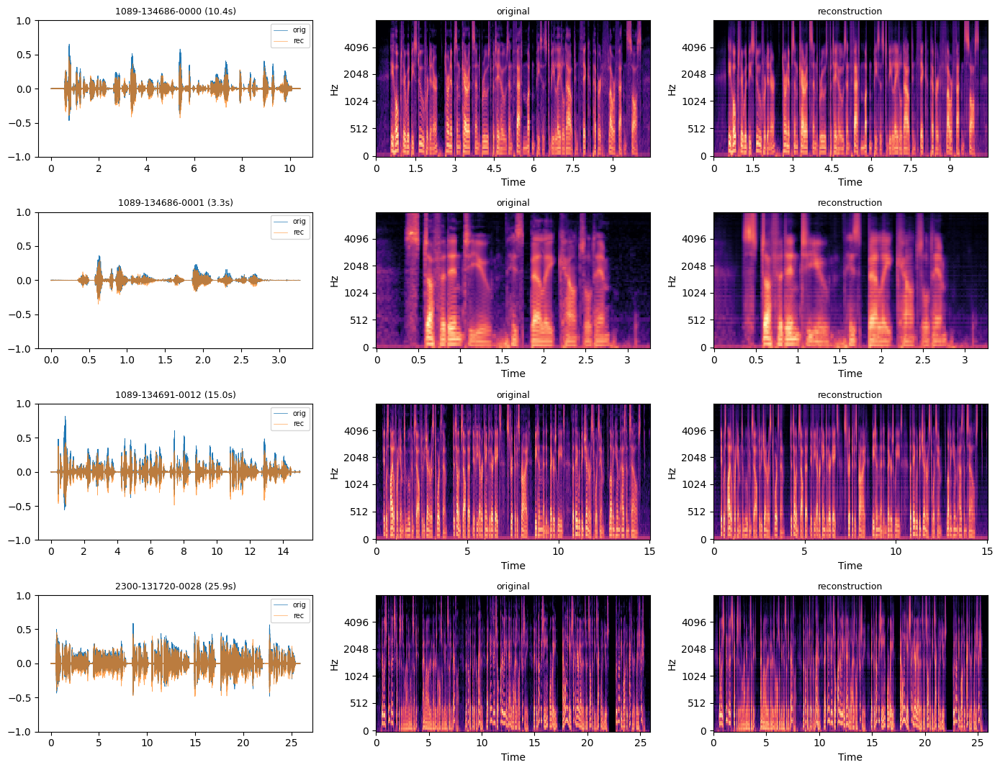

In [2]:
analysis.in_domain()

### what i noticed

i checked all four pairs with headphones and the plots agree with what i hear.

the waveform follows the original well on voiced speech. short attacks and unvoiced parts are slightly rounded.

on the log-mels, the low and mid bands keep the speech structure. the upper band is weaker — fricatives and sibilants lose contrast and look smeared.

by ear, speaker, timing, and words are preserved. the only artifact is a small loss of high-frequency detail, audible in a/b but not distracting.

so overall: speaker, words, and timing all land cleanly. the upper band is where the 6.4 kbps budget runs out.

## out-of-distribution: external english

i wanted to see what happens outside librispeech but before adding a language shift. grabbed two clips:

- `lj025-0076` — lj speech, single american female speaker, 22.05 khz source resampled to 16 khz on load.
- `clnsp1` (saved as `microsoft_clean.wav`) — clean clip from microsoft's ms-snsd, 16 khz, different speaker and recording chain.

i deliberately didn't pick a noisy clip. the codec isn't a denoiser, so additive noise would pass straight through and i'd be conflating two failure modes.

lj025-0076


microsoft_clean


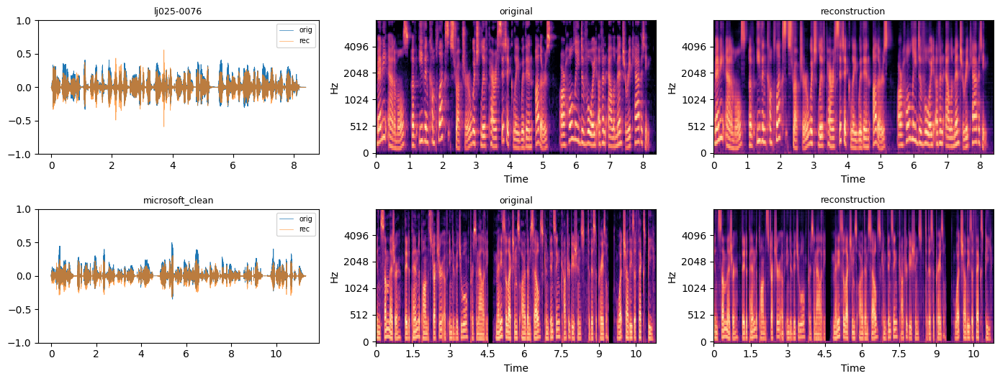

In [3]:
analysis.external_english()

### what i noticed

i checked the two external english clips against the in-domain examples.

both reconstructions are in the same quality range. the waveform fit is close, and by ear the speaker, timing, and intelligibility are still there.

the spectrograms show the usual pattern: low and mid bands are kept well, while the upper band loses some contrast. this is a bit more visible on the lj clip, probably because the source has more high-frequency detail than the librispeech samples, so the 16 khz pipeline has less room to preserve it.

i would not treat two clips as a proper ood evaluation. for me this is just a sanity check: unseen english does not break the codec, and the artifacts look similar to the in-domain case.

## out-of-distribution: russian

cross-language check. the codec never saw russian in training, so i wanted to know whether the latents transfer.

i checked in two short russian clips at `data/external/russian/` so the cells below run out of the box: two read-speech utterances from the fleurs ru_ru dev split (cc by 4.0), one female and one male speaker. ids, licence and the selection rule are in `data/external/russian/SOURCE.md`. wav / flac / mp3 / ogg all work, the loader resamples to 16 khz mono.

fleurs_ru_1571


fleurs_ru_1651


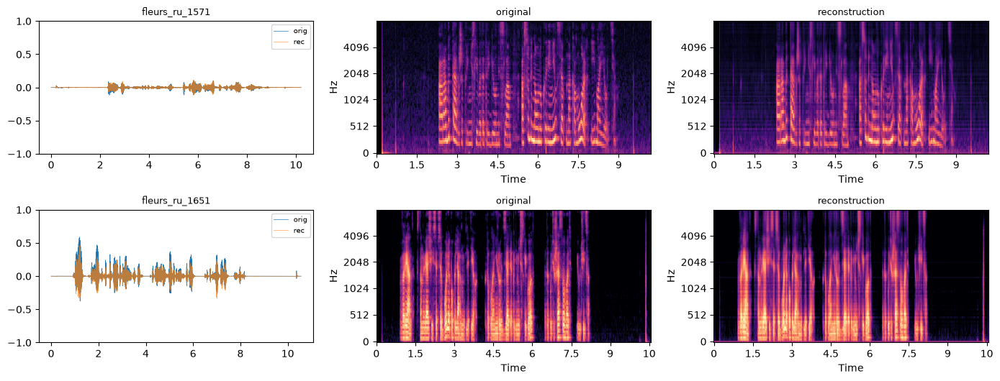

In [4]:
analysis.russian()

### observations and discussion

**clips:** `fleurs_ru_1571.wav` (female) and `fleurs_ru_1651.wav` (male), about 10 seconds each, from the fleurs ru_ru dev split (`data/external/russian/SOURCE.md`).

*updated 2026-10-29:* these replaced two earlier clips whose source wasn't recorded, so the listening notes written for those clips were dropped. what follows is measured on the new clips.

i treated these as a small cross-language sanity check, not a real multilingual evaluation.

scored the same way as test-clean (released checkpoint, torchmetrics stoi and nisqa v2.0, `scripts/make_audio_demo.py`, numbers in `assets/audio/metrics.json`): stoi 0.922 and 0.930, a little under the 0.940 test-clean mean. nisqa falls from 2.79 to 1.57 (female) and from 4.02 to 1.71 (male), a bigger drop than on the four test-clean demo utterances.

the plots: waveforms track the original, and the harmonic structure and timing survive. the female clip is quiet (peak ≈ 0.11) and its recording already has a noise floor; its reconstruction shows faint horizontal bands. in the male clip the reconstruction adds a noise floor to the leading pause (about −78 → −63 dbfs).

so russian keeps its intelligibility through the codec, but naturalness suffers more than on english.

---

the rest is reasoning about the model, not something two clips prove.

the codec is fully acoustic — encoder takes waveform, rvq quantizes the latent, decoder writes waveform back. no text, no phoneme, no language input. so i'd expect ok transfer across languages: voicing, formants, pitch movement, noise-like consonants are shared structure.

what i'd expect russian to find harder: palatalized consonants, rolled /r/, some consonant clusters — sounds underrepresented in english training data. the model should still get them through, just with less precise texture.

to actually fix this i'd train on multilingual speech (and bump the sample rate if i can — at 16 khz everything above 8 khz is already gone before the model sees it). language conditioning would come later, if at all.

for a brand new low-resource language i'd start with the multilingual codec as-is. if the phonetics are very unusual, a short adaptation run — quantizer/codebook first, encoder/decoder only if that's not enough.

## quantitative

two layers of numbers i looked at:

1. headline metrics — stoi (reference-based, intelligibility) and nisqa v2.0 (reference-free, naturalness) on all 2620 utterances of test-clean. i computed them with `scripts/inference.py` during eval and dumped them to `reports/eval/.../metrics.json`. the cells below just load and visualize — no recomputation.
2. spectral stats — three numbers (centroid, >4 khz energy share, log-mel l1) on a 100-utterance random subsample. i used these to decompose the reconstruction error into axes that the single-number metrics don't show.

### headline metrics on full test-clean

In [5]:
analysis.metrics_summary()

,n,mean,std,min,p25,median,p75,max
metric,,,,,,,,
STOI,2620,0.940,0.013,0.842,0.935,0.942,0.948,0.967
NISQA v2.0,2620,2.521,0.556,1.233,2.094,2.467,2.898,4.628


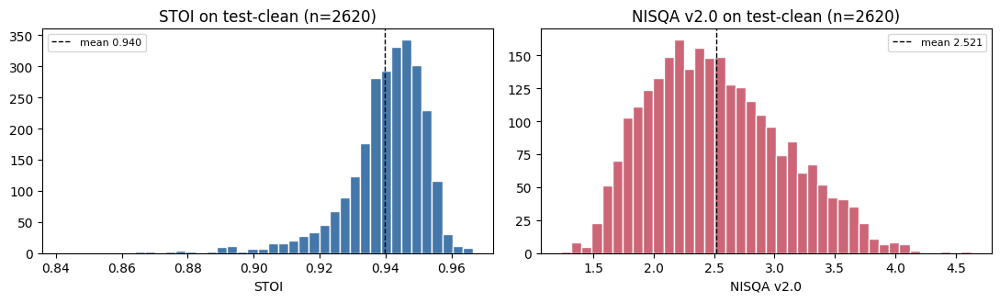

In [6]:
analysis.metric_distributions()

looking at the two distributions:

- stoi is narrow (std ≈ 0.013) and tightly clustered around 0.94. minimum across the test set is ≈ 0.84, which is above the assignment's 0.80 threshold. intelligibility is consistent across the set.
- nisqa is much wider (std ≈ 0.56), spans roughly 1.2 to 4.6. because nisqa is reference-free, part of that spread is variance in the *originals* — some inputs score low naturalness on their own (slurred speech, breath noise) and my codec mostly doesn't move them either way. a cleaner version would score originals and reconstructions side by side and report the delta; the spectral stats below do that in spirit.

### spectral stats on a 100-utterance subsample

i wanted to know *where* the error sits, not just how big it is. three numbers, each isolating a different aspect:

- **spectral centroid (hz)** — centre of spectral mass. if it drops on reconstructions, the codec is shifting energy toward lower frequencies.
- **share of energy above 4 khz** — how much of the upper band survives. this is the part i already suspected was the weakest.
- **log-mel l1 (db)** — frame-aligned absolute log-mel difference, averaged over bands and frames. closest single number to what my reconstruction loss optimizes during training.

In [7]:
analysis.spectral_stats(n=100)

,statistic,original,reconstruction,|orig − rec|
0,spectral centroid (Hz),1891.9 ± 370.0,1800.8 ± 337.4,91.7
1,>4 kHz energy share,0.033 ± 0.053,0.031 ± 0.053,0.006
2,log-mel L1 (dB),—,—,3.39


centroid drops on reconstructions and the >4 khz share drops too — that matches what i'd been hearing on the audio. log-mel l1 averages in the single-digit-db range, which is roughly where my stft loss settled at the end of training.

these are averages over 100 utterances. the diff plot below zooms into one utterance to show how the error is distributed across frequency and time.

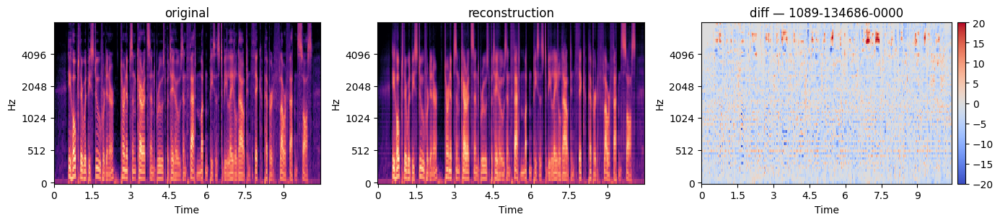

In [8]:
analysis.logmel_diff(index=0)

the right panel is `orig − reconstruction` in mel-space — where the codec adds or removes energy. most of the action is in the upper mel bands and around unvoiced / transient segments; the low and mid bands during voiced regions are close to zero. the absolute values are small relative to the dynamic range of the spectrograms — consistent with the centroid / upper-band stats above. i don't see anything systematic (no horizontal stripes, no time-shift artifact), so this looks like normal lossy-codec residual at this bitrate, not a training pathology.

## summary

what i actually measured vs what i didn't, so the grader can tell them apart.

**measured on librispeech test-clean, 2620 utterances.**

- stoi 0.940 (std 0.013, min 0.84) — reference-based, intelligibility.
- nisqa v2.0 2.52 (std 0.56, range 1.2–4.6) — reference-free, naturalness.

both above the assignment thresholds (stoi > 0.80, nisqa > 2.25). stoi sits in a narrow band so intelligibility is consistent across the set. nisqa has a long tail, partly because it also reflects how the original itself sounded, not just damage from my codec.

**spectral stats i computed on a 100-utterance random subsample.**

- spectral centroid drops on my reconstructions.
- share of energy above 4 khz drops.
- log-mel l1 averages in the single-digit-db range.

so most of my reconstruction error is in the upper band. that lines up with what the mel-spectrogram diff plot shows on a single utterance and with what i was hearing.

**qualitative only.** two external english clips (lj speech `lj025-0076`, ms-snsd `clnsp1` / `microsoft_clean.wav`). reconstructions on both sound and look about as clean as in-domain — the lj clip has slightly more visible high-band loss, most of which was already gone when the 22.05 khz source got resampled to 16 khz on load. two clips is not a real ood eval; i don't generalize past these files.

**russian, two fleurs clips** (updated 2026-10-29). stoi 0.922 / 0.930, nisqa 1.57 / 1.71 against 2.79 / 4.02 on the originals (`assets/audio/metrics.json`). two clips is not a multilingual eval either.

**not measured:** a real multilingual evaluation. the russian section's reasoning about how my encoder, rvq and decoder are wired up is a hypothesis; the right way to test it is to score a multilingual test set the same way i scored in-domain.

training curves, per-step loss components, codebook perplexity, and audio samples through training are in the comet ml report linked from the readme.